# ***Exploratory Data Analysis (EDA)***

## Importing all libraries for EDA

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

## Load Dataset

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "personality_dataset.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,Time_spent_Alone,Time_spent_Alone.1,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4,No,8.0,5.0,Extrovert


Getting shape of dataset

In [3]:
df.shape

(2900, 8)

Getting names of columns

In [4]:
df.columns

Index(['Time_spent_Alone', 'Time_spent_Alone.1', 'Social_event_attendance',
       'Going_outside', 'Drained_after_socializing', 'Friends_circle_size',
       'Post_frequency', 'Personality'],
      dtype='object')

## Getting statistical summary of dataset

In [5]:
df.describe()

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2900.000000,2900.000000,2900.000000,2900.000000,2900.000000
mean,4.505816,3.963354,3.000000,6.268863,3.564727
std,3.441180,2.872608,2.221597,4.232340,2.893587
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,1.000000,3.000000,1.000000
50%,4.000000,3.963354,3.000000,5.000000,3.000000
75%,7.000000,6.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


## Summary of dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2900 non-null   float64
 1   Time_spent_Alone.1         2900 non-null   object 
 2   Social_event_attendance    2900 non-null   float64
 3   Going_outside              2900 non-null   int64  
 4   Drained_after_socializing  2900 non-null   object 
 5   Friends_circle_size        2900 non-null   float64
 6   Post_frequency             2900 non-null   float64
 7   Personality                2900 non-null   object 
dtypes: float64(4), int64(1), object(3)
memory usage: 181.4+ KB


Checking number of "null" values in dataset

In [7]:
df.isnull().sum()

Time_spent_Alone             0
Time_spent_Alone.1           0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
Personality                  0
dtype: int64

Calculating number of duplicates in the dataset

In [8]:
df.duplicated().sum()

np.int64(402)

Dropping all the duplicates except the first value

In [9]:
df1 = df.drop_duplicates(keep='first')
df1.head()

,Time_spent_Alone,Time_spent_Alone.1,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4,No,8.0,5.0,Extrovert


Rechecking shape of dataset after dropping duplicates

In [10]:
df1.shape

(2498, 8)

Getting statistical data again after dropping duplicates

In [11]:
df1.describe()

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000
mean,4.232128,4.200867,3.192954,6.580130,3.815283
std,3.406630,2.874305,2.218807,4.257516,2.914253
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,1.000000,3.000000,1.000000
50%,3.000000,4.000000,3.000000,6.000000,3.000000
75%,7.000000,7.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


## Reindexing the dataset as few duplicate data points are dropped

In [12]:
df1.index = range(1, len(df1) + 1)
df1.head()

,Time_spent_Alone,Time_spent_Alone.1,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
1,4.0,No,4.0,6,No,13.0,5.0,Extrovert
2,9.0,Yes,0.0,0,Yes,0.0,3.0,Introvert
3,9.0,Yes,1.0,2,Yes,5.0,2.0,Introvert
4,0.0,No,6.0,7,No,14.0,8.0,Extrovert
5,3.0,No,9.0,4,No,8.0,5.0,Extrovert


## Defining "introverts" & "extroverts" dataframes from the modified dataframe

In [13]:
introverts = df1[df1['Personality']=='Introvert']
extroverts = df1[df1['Personality']=='Extrovert']

Defining many variables based on introverts

In [14]:
intro_friend_mean, intro_friend_median = introverts['Friends_circle_size'].mean(), introverts['Friends_circle_size'].median()
intro_out_mean, intro_out_median = introverts['Going_outside'].mean(), introverts['Going_outside'].median()
intro_event_mean, intro_event_median = introverts['Social_event_attendance'].mean(), introverts['Social_event_attendance'].median()
intro_post_mean, intro_post_median = introverts['Post_frequency'].mean(), introverts['Post_frequency'].median()
intro_alone_mean, intro_alone_median = introverts['Time_spent_Alone'].mean(), introverts['Time_spent_Alone'].median()

Defining many variables based on introverts

In [15]:
extro_friend_mean, extro_friend_median = extroverts['Friends_circle_size'].mean(), extroverts['Friends_circle_size'].median()
extro_out_mean, extro_out_median = extroverts['Going_outside'].mean(), extroverts['Going_outside'].median()
extro_event_mean, extro_event_median = extroverts['Social_event_attendance'].mean(), extroverts['Social_event_attendance'].median()
extro_post_mean, extro_post_median = extroverts['Post_frequency'].mean(), extroverts['Post_frequency'].median()
extro_alone_mean, extro_alone_median = extroverts['Time_spent_Alone'].mean(), extroverts['Time_spent_Alone'].median()

## Plotting a Pair Plot on modified dataframe with "Personality" as hue

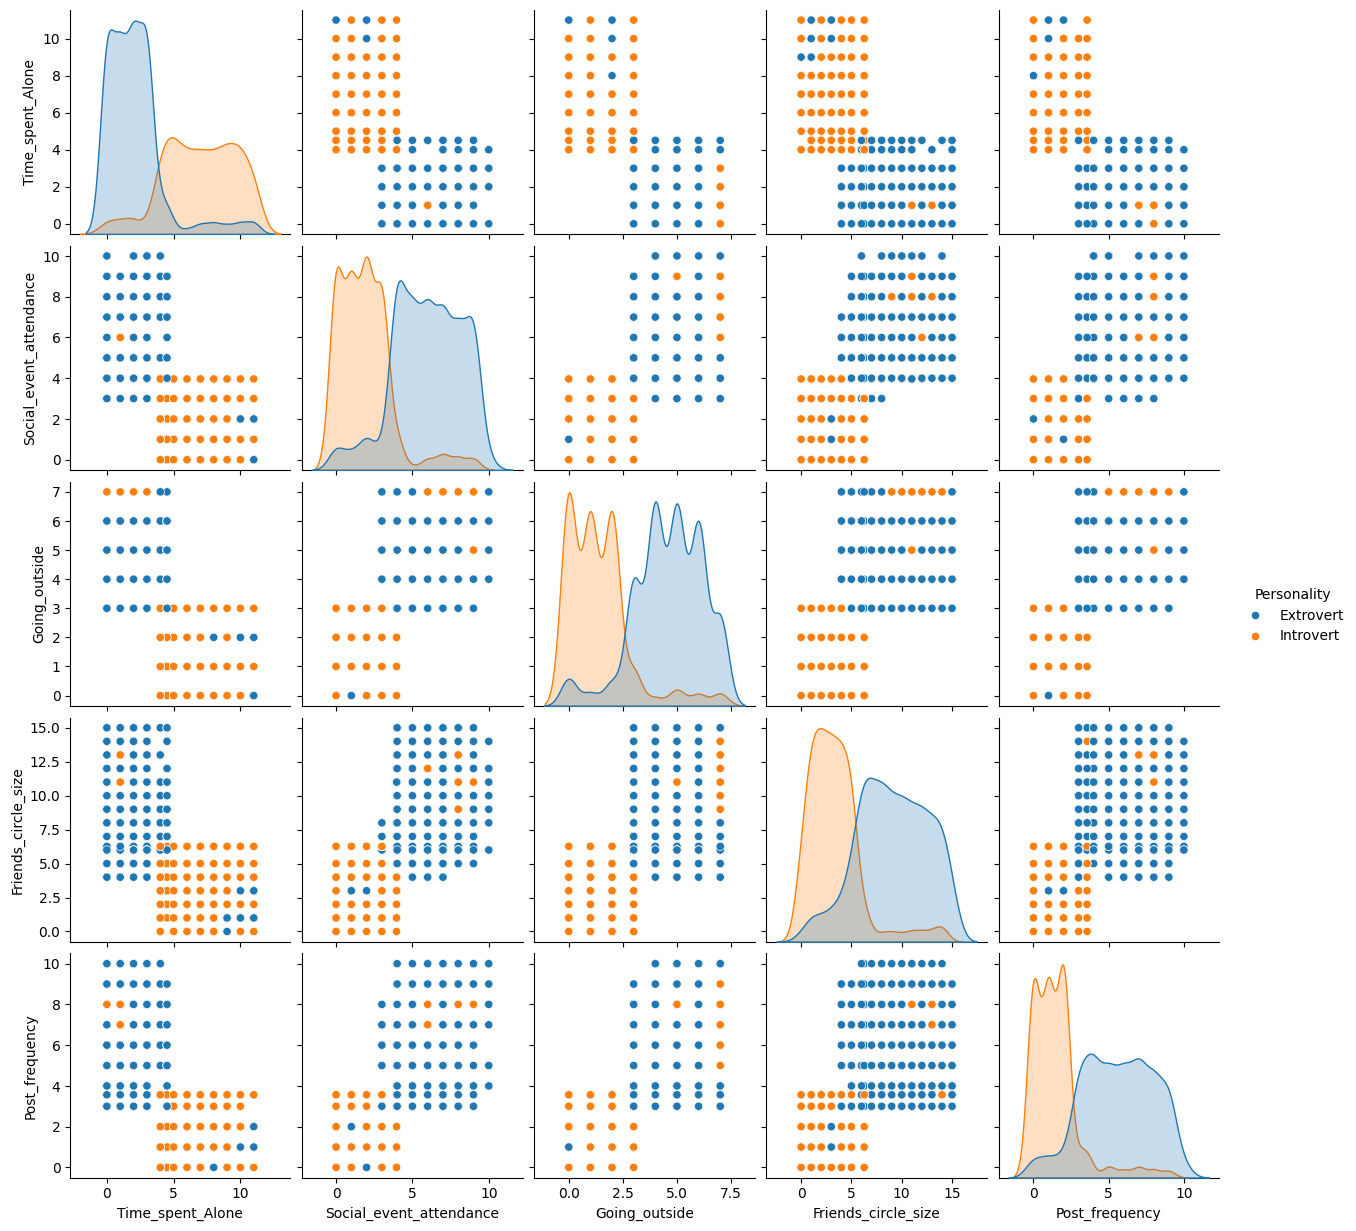

In [16]:
sns.pairplot(data=df1, hue='Personality')
plt.show()

## Correlation Matrix of "introverts" only

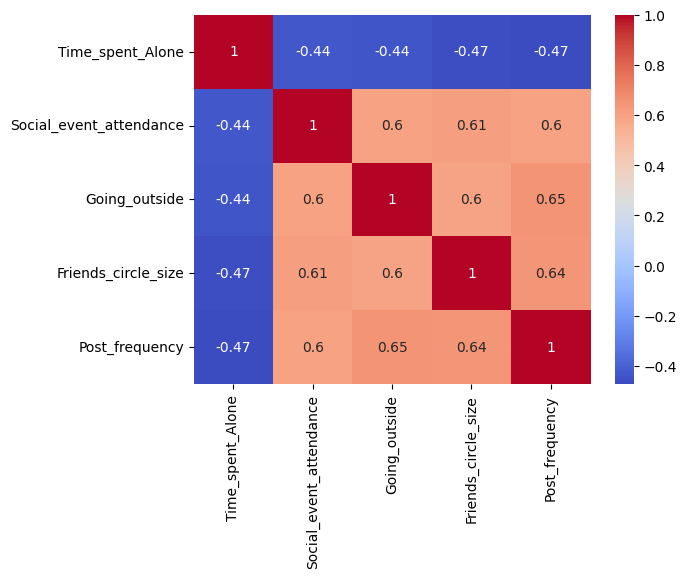

In [17]:
sns.heatmap(introverts.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

## Correlation matrix of "extroverts" only

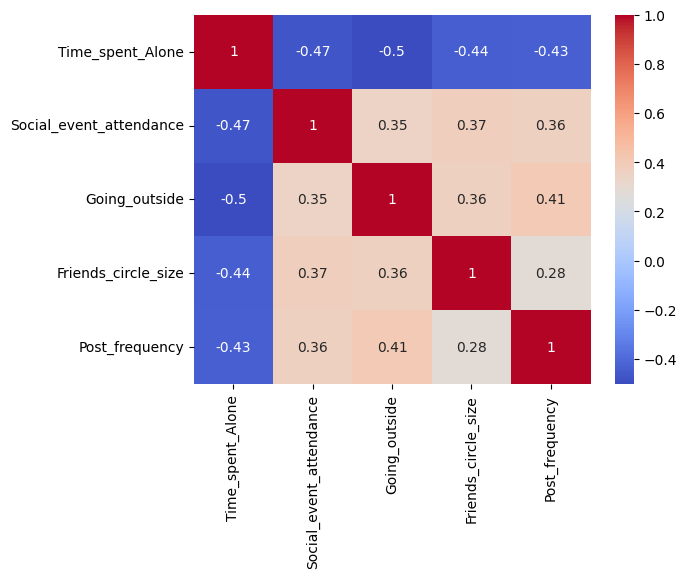

In [18]:
sns.heatmap(extroverts.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

# ***Machine Learning Code***

## Importing all required libraries for classification

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

## Splitting dataset for test set

In [20]:
X = df1[['Time_spent_Alone', 'Social_event_attendance', 'Going_outside', 'Friends_circle_size', 'Post_frequency']]
Y = df1['Personality']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

Predicting the dataset from the test set

In [21]:
lgr = LogisticRegression()
lgr.fit(X_train, Y_train)
import joblib
Y_pred = lgr.predict(X_test)
joblib.dump(lgr, "model.joblib")

['model.joblib']

## Getting a Confusion Matrix & classification report (precision, recall, f1-score)

In [22]:
confusion = confusion_matrix(Y_test, Y_pred)

classification = classification_report(Y_test, Y_pred)

print(confusion)
print(classification)

[[251  28]
 [ 18 203]]
              precision    recall  f1-score   support

   Extrovert       0.93      0.90      0.92       279
   Introvert       0.88      0.92      0.90       221

    accuracy                           0.91       500
   macro avg       0.91      0.91      0.91       500
weighted avg       0.91      0.91      0.91       500



## Calculating Accuracy score on test set

In [23]:
balanced_accuracy_score(Y_test, Y_pred)

0.9090968066300135

## Calculating Score on test set

In [24]:
lgr.score(X_test, Y_test)

0.908

In [25]:
coeff = list(lgr.coef_)
intercept = lgr.intercept_

print(f"Coefficient: {coeff}")
print(f"Intercept: {intercept}")

Coefficient: [array([ 0.137352  , -0.25915749, -0.30392055, -0.06424631, -0.2304828 ])]
Intercept: [2.25019056]


## Manual way to calculate the sigmoid function

In [26]:
def sigmoid(z) :
  sig = 1 / (1 + np.exp(-z))
  return sig

## Calculating Sigmoid function value by taking inputs from user. Also classifies into "introvert" or "extrovert"

In [27]:
X = df1[[
    'Time_spent_Alone',
    'Social_event_attendance',
    'Going_outside',
    'Friends_circle_size',
    'Post_frequency'
]].values.astype(float)
y = (df1['Personality'].values == 'Extrovert').astype(float)

m, n = X.shape
w = np.zeros(n, dtype=float)
b = 0.0
alpha = 0.01
max_iter = 20000
tol = 1e-7
prev_loss = np.inf

for _ in range(max_iter):
    z = X.dot(w) + b
    p = sigmoid(z)
    loss = -np.mean(y * np.log(p + 1e-15) + (1 - y) * np.log(1 - p + 1e-15))
    if abs(prev_loss - loss) < tol:
        break
    prev_loss = loss
    error = p - y
    dw = (X.T @ error) / m
    db = error.mean()
    w -= alpha * dw
    b -= alpha * db

print("Training complete!\n")

alone, event, outside, friends, post = 3, 2, 1, 4, 2
x = np.array([alone, event, outside, friends, post], dtype=float)

z = float(x.dot(w) + b)
p = float(sigmoid(z))
label = 'Extrovert' if p >= 0.5 else 'Introvert'

print(f"Input: alone={alone}, event={event}, outside={outside}, friends={friends}, post={post}")
print(f"Prediction: {label}")
print(f"Probability: {p:.4f}")

Training complete!

Input: alone=3, event=2, outside=1, friends=4, post=2
Prediction: Introvert
Probability: 0.3319


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "WEB").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

app_code = """
from pathlib import Path

import gradio as gr
import joblib
import numpy as np

MODEL_PATH = Path(__file__).resolve().parents[1] / "models" / "model.joblib"
model = joblib.load(MODEL_PATH)

def predict_personality(openness, conscientiousness, extraversion, agreeableness, neuroticism):
    input_array = np.array([[openness, conscientiousness, extraversion, agreeableness, neuroticism]])
    prediction = model.predict(input_array)[0]
    label = "Extrovert" if prediction == 1 else "Introvert"
    return label

demo = gr.Interface(
    fn=predict_personality,
    inputs=[
        gr.Slider(0, 1, step=0.01, label="Openness"),
        gr.Slider(0, 1, step=0.01, label="Conscientiousness"),
        gr.Slider(0, 1, step=0.01, label="Extraversion"),
        gr.Slider(0, 1, step=0.01, label="Agreeableness"),
        gr.Slider(0, 1, step=0.01, label="Neuroticism")
    ],
    outputs=gr.Label(num_top_classes=2),
    title="Extrovert vs Introvert Classifier",
    description="Enter personality trait scores (0 to 1) to predict whether someone is more extroverted or introverted.",
    theme="default"
)

demo.launch()
"""

# Save it as app.py
with open(PROJECT_ROOT / "WEB" / "app.py", "w") as f:
    f.write(app_code)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "WEB").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

with open(PROJECT_ROOT / "WEB" / "requirements.txt", "w") as f:
    f.write("gradio\nscikit-learn\nnumpy\njoblib")

In [ ]:
from pathlib import Path
import zipfile

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "WEB").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

with zipfile.ZipFile(PROJECT_ROOT / "personality_app.zip", "w") as zipf:
    zipf.write(PROJECT_ROOT / "models" / "model.joblib", arcname="model.joblib")
    zipf.write(PROJECT_ROOT / "WEB" / "app.py", arcname="app.py")
    zipf.write(PROJECT_ROOT / "WEB" / "requirements.txt", arcname="requirements.txt")